# Notebook 01r — Preprocessing Sensor (REVISI)
**Basis:** `01_preprocessing_sensor.ipynb` (tidak diubah). Output ke `dataset/revisi/`.

**Apa yang direvisi dan mengapa (komentar editor E1–E2):**
- **E1 – celah waktu.** Interpolasi linear untuk kekosongan panjang (hingga 72 jam) diganti interpolasi hanya untuk kekosongan <=10 baris (`limit_area='inside'`, tanpa `bfill/ffill`). Kekosongan lebih panjang dibiarkan NaN, barisnya dibuang, dan data dipecah menjadi **segmen** (selisih waktu >10 menit = segmen baru) agar model tidak mempelajari garis lurus buatan.
- **E2 – Node 3 anomali.** Node 3 dikeluarkan dari target dan fitur. Datanya disimpan terpisah (`data_node3_qc.csv`) hanya untuk uji sensitivitas, disertai sel QC.
- Bacaan 0 pada suhu dan kelembaban udara kini dianggap gagal baca (NaN).
- Data dibatasi sampai `waktu_pembacaan <= 2026-10-19 08:50:06` (periode naskah).
- Kredensial DB dibaca dari `.env`. Database hanya dibaca (SELECT).

In [1]:
# -- CELL 1: Import Library --------------------------------------
import os, json, warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from sqlalchemy import create_engine, text

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)
plt.style.use('seaborn-v0_8-whitegrid')

OUT = 'dataset/revisi'
os.makedirs(OUT, exist_ok=True)
BATAS_WAKTU = '2026-10-19 08:50:06'
MAX_RUN     = 10        # kekosongan maksimum (baris) yang boleh diinterpolasi
GAP_MENIT   = 10        # selisih waktu > ini => segmen baru
print('[OK] Library diimport | pandas', pd.__version__)

[OK] Library diimport | pandas 3.0.3


In [2]:
# -- CELL 2: Koneksi DB (dari .env) & Load Data (SELECT saja) ----
load_dotenv()
url = (f"mysql+pymysql://{os.environ['DB_USER']}:{os.environ['DB_PASS']}"
       f"@{os.environ['DB_HOST']}:{os.environ['DB_PORT']}/{os.environ['DB_NAME']}")
engine = create_engine(url)

query = text("SELECT * FROM sensor_readings WHERE waktu_pembacaan <= :batas "
             "ORDER BY waktu_pembacaan ASC")
with engine.connect() as conn:
    df_raw = pd.read_sql(query, conn, params={'batas': BATAS_WAKTU})

print('=== Informasi Data Mentah ===')
print(f'Jumlah baris : {df_raw.shape[0]:,}')
print(f'Kolom        : {list(df_raw.columns)}')
print(f'Periode      : {df_raw["waktu_pembacaan"].min()} -> {df_raw["waktu_pembacaan"].max()}')
print(df_raw.head(3))

=== Informasi Data Mentah ===
Jumlah baris : 120,145
Kolom        : ['id', 'sensor_tanah_adc_1', 'kelembaban_tanah_1', 'kelembaban_udara_1', 'tekanan_udara_1', 'suhu_udara_1', 'sensor_tanah_adc_2', 'kelembaban_tanah_2', 'kelembaban_udara_2', 'tekanan_udara_2', 'suhu_udara_2', 'sensor_tanah_adc_3', 'kelembaban_tanah_3', 'kelembaban_udara_3', 'tekanan_udara_3', 'suhu_udara_3', 'curah_hujan', 'backup_status', 'waktu_pembacaan', 'created_at', 'updated_at']
Periode      : 2026-07-10 11:16:24 -> 2026-10-19 08:50:06
   id  sensor_tanah_adc_1  kelembaban_tanah_1  kelembaban_udara_1  \
0   1           1791.0000             88.0000             39.7500   
1   2           1817.0000             86.0000             39.0200   
2   3           1811.0000             86.0000             40.6200   

   tekanan_udara_1  suhu_udara_1  sensor_tanah_adc_2  kelembaban_tanah_2  \
0        1013.7460       41.5800           1909.0000             91.0000   
1        1013.7810       40.8400           1907.0000    

In [3]:
# -- CELL 3: Analisis Missing Values -----------------------------
miss = df_raw.isnull().sum()
print(pd.DataFrame({'Missing': miss, 'Persen': (miss/len(df_raw)*100).round(3)})
      .query('Missing > 0') if miss.any() else '[OK] Tidak ada missing value')

[OK] Tidak ada missing value


In [4]:
# -- CELL 4: Analisis Nilai Nol per Kolom ------------------------
sensor_cols = [c for c in [
    'kelembaban_tanah_1','kelembaban_tanah_2','kelembaban_tanah_3',
    'kelembaban_udara_1','kelembaban_udara_2','kelembaban_udara_3',
    'suhu_udara_1','suhu_udara_2','suhu_udara_3',
    'tekanan_udara_1','tekanan_udara_2','tekanan_udara_3','curah_hujan'] if c in df_raw.columns]
z = (df_raw[sensor_cols] == 0).sum()
print(pd.DataFrame({'Jumlah_Nol': z, 'Persen(%)': (z/len(df_raw)*100).round(3)}))

                    Jumlah_Nol  Persen(%)
kelembaban_tanah_1        1656     1.3780
kelembaban_tanah_2        8100     6.7420
kelembaban_tanah_3        9793     8.1510
kelembaban_udara_1        1656     1.3780
kelembaban_udara_2        8100     6.7420
kelembaban_udara_3        9793     8.1510
suhu_udara_1              1656     1.3780
suhu_udara_2              8100     6.7420
suhu_udara_3              9793     8.1510
tekanan_udara_1           1656     1.3780
tekanan_udara_2           8100     6.7420
tekanan_udara_3           9793     8.1510
curah_hujan             118444    98.5840


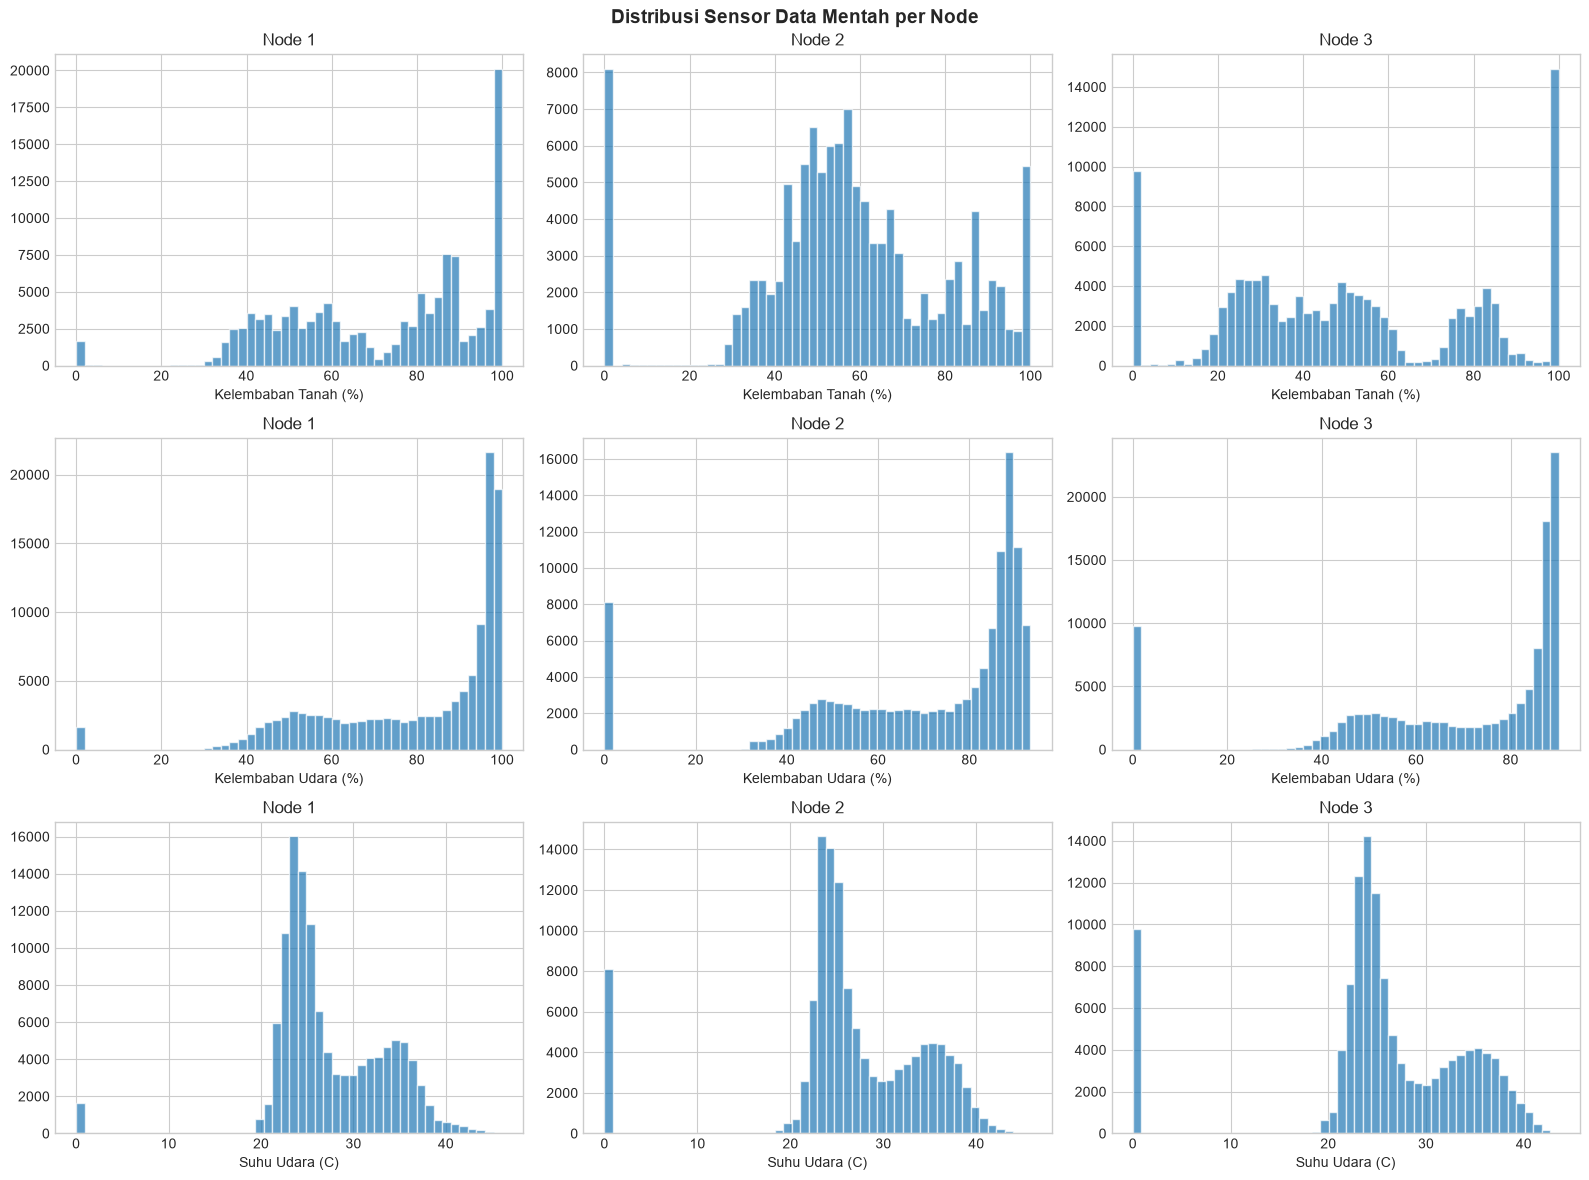

In [5]:
# -- CELL 5: Distribusi Data Mentah ------------------------------
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
fig.suptitle('Distribusi Sensor Data Mentah per Node', fontsize=14, fontweight='bold')
groups = [(['kelembaban_tanah_1','kelembaban_tanah_2','kelembaban_tanah_3'], 'Kelembaban Tanah (%)'),
          (['kelembaban_udara_1','kelembaban_udara_2','kelembaban_udara_3'], 'Kelembaban Udara (%)'),
          (['suhu_udara_1','suhu_udara_2','suhu_udara_3'], 'Suhu Udara (C)')]
for r, (cols, yl) in enumerate(groups):
    for ci, col in enumerate(cols):
        axes[r][ci].hist(df_raw[col].dropna(), bins=50, alpha=0.7, edgecolor='white')
        axes[r][ci].set_title(f'Node {ci+1}'); axes[r][ci].set_xlabel(yl)
plt.tight_layout()
plt.savefig(f'{OUT}/plot_distribusi_raw_revisi.png', dpi=150, bbox_inches='tight')
plt.show()

In [6]:
# -- CELL 6a-6e: langkah awal (sama seperti notebook lama) --------
LAPORAN = {'baris_awal': int(len(df_raw)), 'batas_waktu_data': BATAS_WAKTU}
df = df_raw.copy()

# 6a. waktu
df['waktu_pembacaan'] = pd.to_datetime(df['waktu_pembacaan'], errors='coerce')
LAPORAN['dibuang_timestamp_invalid'] = int(df['waktu_pembacaan'].isna().sum())
df = df.dropna(subset=['waktu_pembacaan']).sort_values('waktu_pembacaan').reset_index(drop=True)

# 6b. duplikat timestamp
LAPORAN['dibuang_duplikat'] = int(df.duplicated(subset=['waktu_pembacaan']).sum())
df = df.drop_duplicates(subset=['waktu_pembacaan'], keep='first').reset_index(drop=True)

# 6c. kolom tak dipakai
drop_cols = ['id','backup_status','created_at','updated_at',
             'sensor_tanah_adc_1','sensor_tanah_adc_2','sensor_tanah_adc_3']
df = df.drop(columns=[c for c in drop_cols if c in df.columns])

# 6d. numerik
num_cols = [c for c in df.columns if c != 'waktu_pembacaan']
df[num_cols] = df[num_cols].apply(pd.to_numeric, errors='coerce')

# 6e. ketiga sensor tanah = 0
kt_cols = ['kelembaban_tanah_1','kelembaban_tanah_2','kelembaban_tanah_3']
m = (df[kt_cols] == 0).all(axis=1)
LAPORAN['dibuang_semua_sensor_tanah_nol'] = int(m.sum())
df = df[~m].reset_index(drop=True)

# Lonjakan pada data setelah 6e (nol belum ditangani) untuk QC
df_pasca6e = df[['waktu_pembacaan'] + kt_cols].copy()

for k in ['dibuang_timestamp_invalid','dibuang_duplikat','dibuang_semua_sensor_tanah_nol']:
    print(f'{k}: {LAPORAN[k]:,}')
print(f'Baris setelah 6a-6e: {len(df):,}')

# Segmen awal (seg0) HANYA untuk interpolasi: agar nilai tidak diinterpolasi melintasi celah waktu
df['seg0'] = (df['waktu_pembacaan'].diff() > pd.Timedelta(minutes=GAP_MENIT)).cumsum()

def interp_pendek(s, maxrun=MAX_RUN):
    """Interpolasi linear hanya untuk run NaN <= maxrun baris (limit_area='inside').
    Run NaN lebih panjang dibiarkan NaN seluruhnya (bukan terisi sebagian)."""
    isn = s.isna()
    rid = (isn != isn.shift()).cumsum()
    runlen = isn.groupby(rid).transform('sum')
    filled = s.interpolate(method='linear', limit_area='inside')
    return filled.where(~(isn & (runlen > maxrun)), np.nan)

def bersihkan(col, mask_invalid):
    """Tandai invalid -> NaN, interpolasi pendek per seg0. Kembalikan (n_invalid, n_tersisa_NaN)."""
    n = int(mask_invalid.sum())
    df.loc[mask_invalid, col] = np.nan
    df[col] = df.groupby('seg0')[col].transform(interp_pendek)
    return n, int(df[col].isna().sum())

dibuang_timestamp_invalid: 0
dibuang_duplikat: 0
dibuang_semua_sensor_tanah_nol: 1,656
Baris setelah 6a-6e: 118,489


In [7]:
# -- CELL 6f-6h: nol/invalid -> NaN, interpolasi pendek -----------
rin = {}
# 6f. nol pada kelembaban tanah
for c in kt_cols:
    rin[c] = bersihkan(c, df[c] == 0)
# 6g. tekanan di luar 800-1100 hPa
for c in ['tekanan_udara_1','tekanan_udara_2','tekanan_udara_3']:
    rin[c] = bersihkan(c, (df[c] < 800) | (df[c] > 1100))
# 6h. kelembaban udara >100 atau 0 ; suhu udara 0 (BARU)
for c in ['kelembaban_udara_1','kelembaban_udara_2','kelembaban_udara_3']:
    rin[c] = bersihkan(c, (df[c] > 100) | (df[c] == 0))
for c in ['suhu_udara_1','suhu_udara_2','suhu_udara_3']:
    rin[c] = bersihkan(c, df[c] == 0)

print(f'{"kolom":<22}{"invalid":>9}{"NaN tersisa":>13}')
for c, (n, left) in rin.items():
    print(f'{c:<22}{n:>9,}{left:>13,}')
LAPORAN['invalid_dan_nan_tersisa_per_kolom'] = {c: {'invalid': a, 'nan_tersisa': b} for c, (a, b) in rin.items()}

kolom                   invalid  NaN tersisa
kelembaban_tanah_1            0            0
kelembaban_tanah_2        6,444        6,440
kelembaban_tanah_3        8,137        8,137
tekanan_udara_1               0            0
tekanan_udara_2           6,444        6,440
tekanan_udara_3           8,137        8,137
kelembaban_udara_1            0            0
kelembaban_udara_2        6,444        6,440
kelembaban_udara_3        8,137        8,137
suhu_udara_1                  0            0
suhu_udara_2              6,444        6,440
suhu_udara_3              8,137        8,137


In [8]:
# -- CELL 6i: Outlier (aturan LAMA) -- hitung dulu, JANGAN ubah ---
cnt_out = {}
for c in kt_cols:
    s = df[c].dropna()
    q1, q3 = s.quantile(0.01), s.quantile(0.99)
    iqr = q3 - q1
    low, high = max(q1 - 3*iqr, 0.0), min(q3 + 3*iqr, 100.0)
    mask = (df[c] < low) | (df[c] > high)
    cnt_out[c] = {'batas_bawah': float(low), 'batas_atas': float(high), 'jumlah_outlier': int(mask.sum())}
    print(f'{c}: batas [{low:.1f}, {high:.1f}] -> {int(mask.sum()):,} nilai kena aturan outlier lama')
LAPORAN['outlier_aturan_lama'] = cnt_out

kelembaban_tanah_1: batas [0.0, 100.0] -> 0 nilai kena aturan outlier lama
kelembaban_tanah_2: batas [0.0, 100.0] -> 0 nilai kena aturan outlier lama
kelembaban_tanah_3: batas [0.0, 100.0] -> 0 nilai kena aturan outlier lama


In [9]:
# -- CELL 6i (lanjutan): keputusan pengguna -----------------------
OUTLIER_MODE = 'keep'   # 'keep' = nilai outlier -> NaN lalu interpolasi pendek ; 'drop' = langkah dihapus
LAPORAN['outlier_mode'] = OUTLIER_MODE
if OUTLIER_MODE == 'keep':
    for c in kt_cols:
        n, _ = bersihkan(c, (df[c] < cnt_out[c]['batas_bawah']) | (df[c] > cnt_out[c]['batas_atas']))
        print(f'{c}: {n:,} outlier -> NaN -> interpolasi pendek')
else:
    print('Langkah 6i (outlier) dihapus sesuai keputusan.')

kelembaban_tanah_1: 0 outlier -> NaN -> interpolasi pendek
kelembaban_tanah_2: 0 outlier -> NaN -> interpolasi pendek
kelembaban_tanah_3: 0 outlier -> NaN -> interpolasi pendek


In [10]:
# -- CELL 6j: pemilihan node (Node 1 & 2 + curah hujan) ----------
MODEL_COLS = ['kelembaban_tanah_1','kelembaban_tanah_2',
              'kelembaban_udara_1','kelembaban_udara_2',
              'suhu_udara_1','suhu_udara_2',
              'tekanan_udara_1','tekanan_udara_2','curah_hujan']
NODE3_COLS = ['kelembaban_tanah_3','kelembaban_udara_3','suhu_udara_3','tekanan_udara_3']
df_all = df[['waktu_pembacaan'] + MODEL_COLS + NODE3_COLS].copy()
df_all.to_csv(f'{OUT}/data_node3_qc.csv', index=False)   # semua node (NaN masih ada) -> sensitivitas Node 3
print(f'[OK] {OUT}/data_node3_qc.csv ({len(df_all):,} baris, semua node, setelah pembersihan)')

# -- CELL 6k: buang baris tidak valid ----------------------------
n0 = len(df_all)
na = df_all[MODEL_COLS].isna()
dibuang_kt1 = int(na['kelembaban_tanah_1'].sum())
dibuang_kt2 = int(na['kelembaban_tanah_2'].sum())
dibuang_lain = int((na.drop(columns=['kelembaban_tanah_1','kelembaban_tanah_2']).any(axis=1)
                    & ~na[['kelembaban_tanah_1','kelembaban_tanah_2']].any(axis=1)).sum())
dv = df_all.dropna(subset=MODEL_COLS).copy()
LAPORAN['baris_dibuang_kekosongan_panjang'] = {
    'node1_kt_nan': dibuang_kt1, 'node2_kt_nan': dibuang_kt2,
    'hanya_kolom_lain_nan': dibuang_lain, 'total_dibuang': int(n0 - len(dv))}
print(f'Baris dibuang: total {n0-len(dv):,} | NaN kt1={dibuang_kt1:,} kt2={dibuang_kt2:,} | hanya kolom lain={dibuang_lain:,}')

# -- CELL 6l: segmentasi -----------------------------------------
dv = dv.sort_values('waktu_pembacaan').reset_index(drop=True)
dv['segmen'] = ((dv['waktu_pembacaan'].diff() > pd.Timedelta(minutes=GAP_MENIT)).cumsum()).astype(int)
dv['kelembaban_tanah_avg'] = dv[['kelembaban_tanah_1','kelembaban_tanah_2']].mean(axis=1)

seg = dv.groupby('segmen')['waktu_pembacaan'].agg(['min','max','count'])
seg['durasi_jam'] = (seg['max'] - seg['min']).dt.total_seconds()/3600
seg24 = seg[seg['durasi_jam'] >= 24]
gap_terpanjang = dv['waktu_pembacaan'].diff().max()
ig = dv['waktu_pembacaan'].diff().idxmax()

print(f'Baris awal            : {LAPORAN["baris_awal"]:,}')
print(f'Baris valid           : {len(dv):,}')
print(f'Jumlah segmen         : {len(seg)}')
print(f'Segmen >= 24 jam      : {len(seg24)}  ({seg24["count"].sum()/len(dv)*100:.1f}% data)')
print(f'Celah terpanjang      : {gap_terpanjang}  ({dv.loc[ig-1,"waktu_pembacaan"]} -> {dv.loc[ig,"waktu_pembacaan"]})')
sebelum, sesudah = dv.iloc[:ig], dv.iloc[ig:]
deret = [{'nama': 'sebelum celah terpanjang', 'awal': str(sebelum['waktu_pembacaan'].min()), 'akhir': str(sebelum['waktu_pembacaan'].max()), 'baris': int(len(sebelum))},
         {'nama': 'sesudah celah terpanjang', 'awal': str(sesudah['waktu_pembacaan'].min()), 'akhir': str(sesudah['waktu_pembacaan'].max()), 'baris': int(len(sesudah))}]
print('Dua deret utama (dipisah oleh celah terpanjang):')
for d in deret:
    print(f"   {d['nama']}: {d['awal']} -> {d['akhir']}  ({d['baris']:,} baris)")

LAPORAN.update({
    'baris_valid': int(len(dv)), 'jumlah_segmen': int(len(seg)),
    'jumlah_segmen_ge_24jam': int(len(seg24)),
    'persen_data_di_segmen_ge_24jam': float(seg24['count'].sum()/len(dv)*100),
    'celah_terpanjang': {'durasi': str(gap_terpanjang),
                         'dari': str(dv.loc[ig-1,'waktu_pembacaan']), 'sampai': str(dv.loc[ig,'waktu_pembacaan'])},
    'dua_deret_utama': deret,
    'periode_awal': str(dv['waktu_pembacaan'].min()), 'periode_akhir': str(dv['waktu_pembacaan'].max()),
})

[OK] dataset/revisi/data_node3_qc.csv (118,489 baris, semua node, setelah pembersihan)
Baris dibuang: total 6,440 | NaN kt1=0 kt2=6,440 | hanya kolom lain=0
Baris awal            : 120,145
Baris valid           : 112,049
Jumlah segmen         : 40
Segmen >= 24 jam      : 8  (90.9% data)
Celah terpanjang      : 13 days 13:33:23  (2026-07-27 01:14:25 -> 2026-08-09 14:47:48)
Dua deret utama (dipisah oleh celah terpanjang):
   sebelum celah terpanjang: 2026-07-10 11:16:24 -> 2026-07-27 01:14:25  (20,852 baris)
   sesudah celah terpanjang: 2026-08-09 14:47:48 -> 2026-10-19 08:50:06  (91,197 baris)


In [11]:
# -- QC NODE 3 ----------------------------------------------------
qc = {}
t = df_pasca6e['waktu_pembacaan']
d1 = t.diff() <= pd.Timedelta(minutes=2)        # hanya selisih antar-baris yang ~1 menit
for i, c in enumerate(kt_cols, 1):
    lonjakan_mentah = int(((df_pasca6e[c].diff().abs() > 20) & d1).sum())
    s = df_all['kelembaban_tanah_%d' % i]
    lonjakan_bersih = int(((s.diff().abs() > 20) & (df_all['waktu_pembacaan'].diff() <= pd.Timedelta(minutes=2))).sum())
    sub = df_all.loc[df_all['waktu_pembacaan'] >= '2026-09-30', 'kelembaban_tanah_%d' % i].dropna()
    qc[f'node{i}'] = {
        'jumlah_nol_mentah': int((df_raw[c] == 0).sum()),
        'lonjakan_abs_diff_gt20_mentah': lonjakan_mentah,
        'lonjakan_abs_diff_gt20_setelah_cleaning': lonjakan_bersih,
        'persen_waktu_ge_99_sejak_30sep': float((sub >= 99).mean()*100) if len(sub) else None,
        'n_sejak_30sep': int(len(sub)),
    }
sd3 = df_all.loc[df_all['waktu_pembacaan'] >= '2026-10-09', 'kelembaban_tanah_3'].dropna()
qc['node3_std_sejak_9okt'] = float(sd3.std()) if len(sd3) else None
qc['node3_mean_sejak_9okt'] = float(sd3.mean()) if len(sd3) else None
# Nilai tersering (modus) tiap node pada data mentah
qc['modus_mentah'] = {f'node{i}': float(df_raw[c].mode().iloc[0]) for i, c in enumerate(kt_cols, 1)}
print(json.dumps(qc, indent=2))
LAPORAN['qc_node3'] = qc

{
  "node1": {
    "jumlah_nol_mentah": 1656,
    "lonjakan_abs_diff_gt20_mentah": 114,
    "lonjakan_abs_diff_gt20_setelah_cleaning": 114,
    "persen_waktu_ge_99_sejak_30sep": 21.004039238315062,
    "n_sejak_30sep": 25995
  },
  "node2": {
    "jumlah_nol_mentah": 8100,
    "lonjakan_abs_diff_gt20_mentah": 352,
    "lonjakan_abs_diff_gt20_setelah_cleaning": 324,
    "persen_waktu_ge_99_sejak_30sep": 0.013537906137184115,
    "n_sejak_30sep": 22160
  },
  "node3": {
    "jumlah_nol_mentah": 9793,
    "lonjakan_abs_diff_gt20_mentah": 1302,
    "lonjakan_abs_diff_gt20_setelah_cleaning": 1300,
    "persen_waktu_ge_99_sejak_30sep": 64.22064777327935,
    "n_sejak_30sep": 21736
  },
  "node3_std_sejak_9okt": 1.5866338226756513,
  "node3_mean_sejak_9okt": 99.68570647717955,
  "modus_mentah": {
    "node1": 100.0,
    "node2": 0.0,
    "node3": 100.0
  }
}


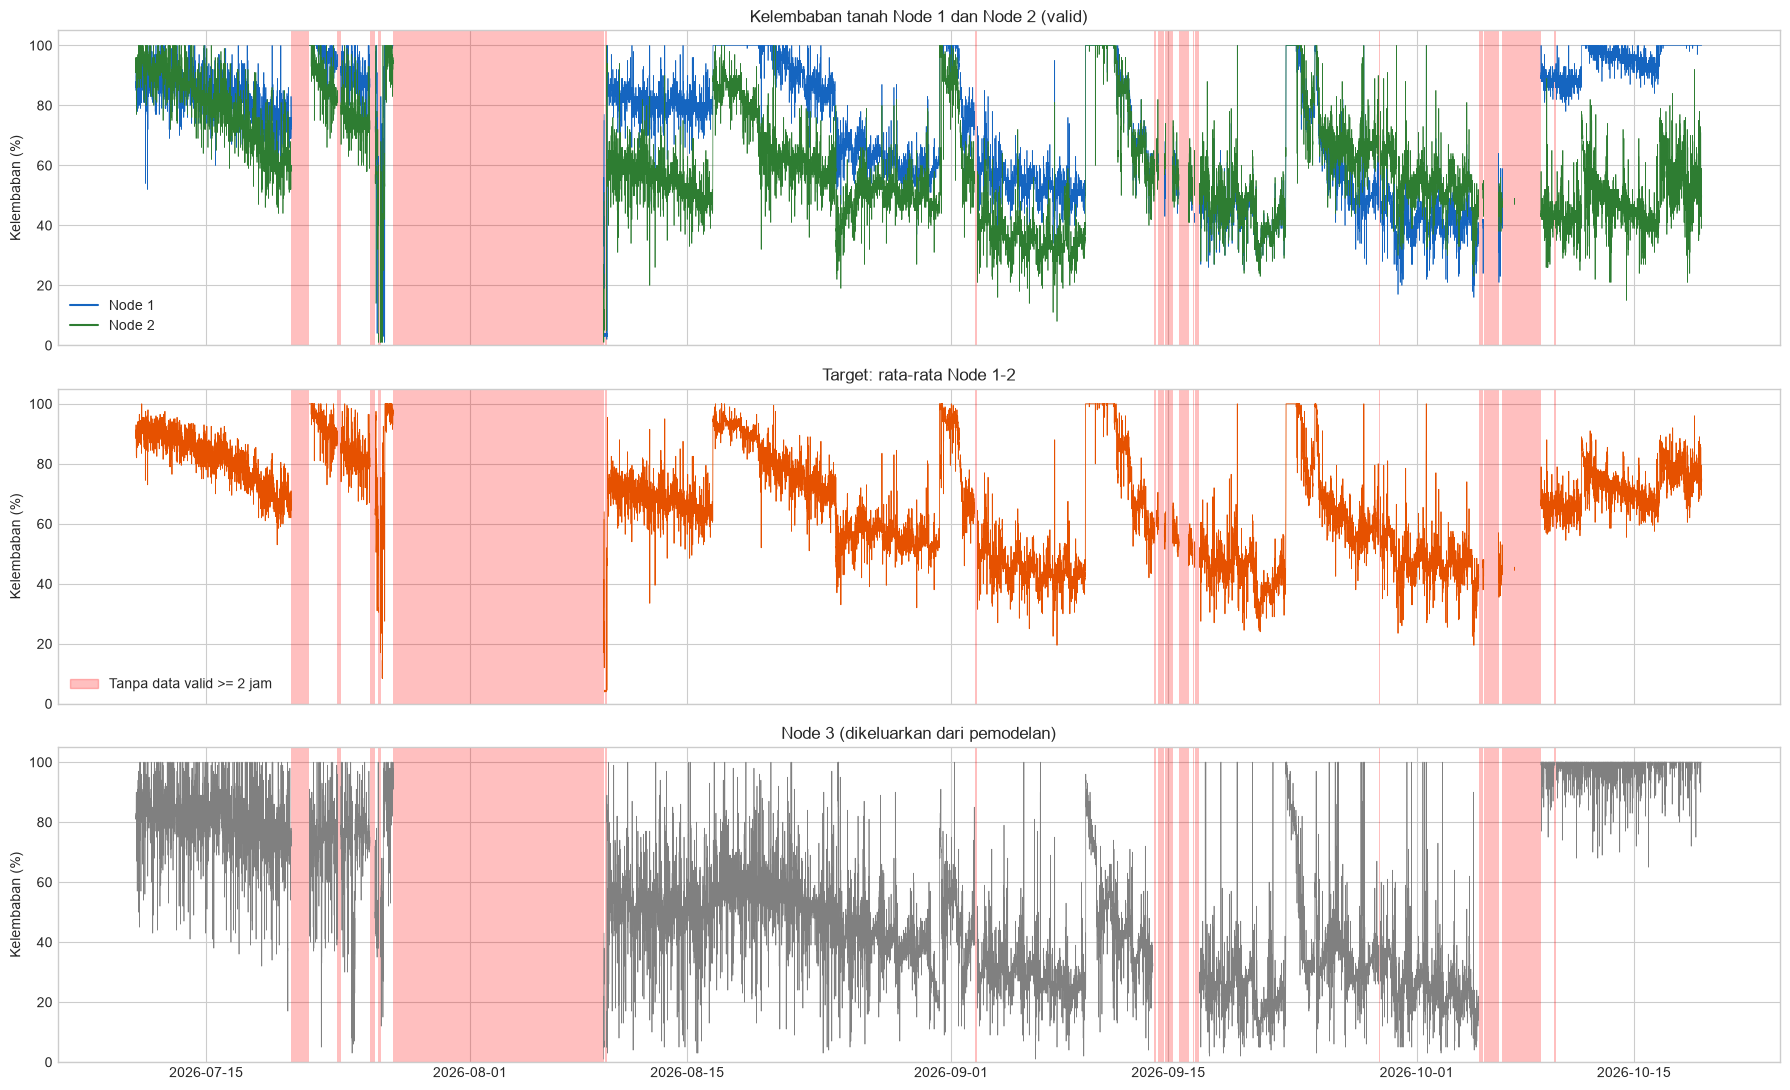

In [12]:
# -- CELL 8: Plot deret waktu -------------------------------------
gaps = dv['waktu_pembacaan'].diff()
gap_idx = gaps[gaps >= pd.Timedelta(hours=2)].index

def arsir(ax):
    for i in gap_idx:
        ax.axvspan(dv.loc[i-1,'waktu_pembacaan'], dv.loc[i,'waktu_pembacaan'], color='red', alpha=0.25, lw=0)

fig, axes = plt.subplots(3, 1, figsize=(18, 11), sharex=True)
for ax in axes: arsir(ax)
# garis diputus per segmen (tidak menyambung melintasi celah)
for _, g in dv.groupby('segmen'):
    axes[0].plot(g['waktu_pembacaan'], g['kelembaban_tanah_1'], lw=0.5, color='#1565C0')
    axes[0].plot(g['waktu_pembacaan'], g['kelembaban_tanah_2'], lw=0.5, color='#2E7D32')
    axes[1].plot(g['waktu_pembacaan'], g['kelembaban_tanah_avg'], lw=0.6, color='#E65100')
# Node 3: putus pada celah > GAP_MENIT di data node-3 yang valid
n3 = df_all[['waktu_pembacaan','kelembaban_tanah_3']].dropna()
for _, g in n3.groupby((n3['waktu_pembacaan'].diff() > pd.Timedelta(minutes=GAP_MENIT)).cumsum()):
    axes[2].plot(g['waktu_pembacaan'], g['kelembaban_tanah_3'], lw=0.5, color='gray')
from matplotlib.lines import Line2D
axes[0].legend(handles=[Line2D([0],[0],color='#1565C0',label='Node 1'), Line2D([0],[0],color='#2E7D32',label='Node 2')], loc='lower left')
axes[0].set_title('Kelembaban tanah Node 1 dan Node 2 (valid)')
axes[1].set_title('Target: rata-rata Node 1-2')
axes[2].set_title('Node 3 (dikeluarkan dari pemodelan)')
for ax in axes: ax.set_ylim(0, 105); ax.set_ylabel('Kelembaban (%)')
from matplotlib.patches import Patch
axes[1].legend(handles=[Patch(color='red', alpha=0.25, label='Tanpa data valid >= 2 jam')], loc='lower left')
plt.tight_layout()
plt.savefig(f'{OUT}/plot_timeseries_revisi.png', dpi=150, bbox_inches='tight')
plt.show()

In [13]:
# -- CELL 9: Simpan -----------------------------------------------
final_cols = ['waktu_pembacaan','segmen'] + MODEL_COLS
dv[final_cols].to_csv(f'{OUT}/data_cleaned_revisi.csv', index=False)
LAPORAN['kolom_pemodelan'] = MODEL_COLS
with open(f'{OUT}/cleaning_report_revisi.json', 'w') as f:
    json.dump(LAPORAN, f, indent=2, default=str)
print(f'[OK] {OUT}/data_cleaned_revisi.csv  ({len(dv):,} baris, {dv["segmen"].nunique()} segmen)')
print(f'[OK] {OUT}/cleaning_report_revisi.json')

[OK] dataset/revisi/data_cleaned_revisi.csv  (112,049 baris, 40 segmen)
[OK] dataset/revisi/cleaning_report_revisi.json
